# SCRUM-22 | 제공 샘플 데이터 EDA

목적: 샘플 4개 테이블의 행/컬럼, 결측, 기본 수율 지표, 데이터 사전 후보, 키 관계, 시점 일관성 확인.

**주의:** 이는 실제 운영 수율을 평가하는 모델이 아니라 **합성/제공 샘플의 데이터 상태를 확인**하는 분석입니다. 원본 데이터 값은 수정하지 않았습니다.

In [1]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

root = Path.cwd()
if not (root / 'data').exists():
    root = root.parent
assert (root / 'data').exists(), '프로젝트 루트 또는 notebooks 폴더에서 실행하세요.'

names = ['yield_monitoring', 'process_condition', 'root_cause_analysis', 'improvement_tracking']
tables = {name: pd.read_csv(root / 'data' / f'{name}.csv', encoding='utf-8-sig') for name in names}
for name, df in tables.items():
    print(f'{name}: {len(df)}행 × {len(df.columns)}열')
    display(df.head(3))

yield_monitoring: 100행 × 17열


,yield_id,equipment_id,process_id,product,operator_id,shift,target_yield,actual_yield,yield_gap,yield_status,input_qty,output_qty,defect_qty,loss_qty,detection_yn,consecutive_low_cnt,measured_at
0,YM-0001,EQP-009,PROC-05,PRD-A,OP-001,주간,93.2,91.9,1.3,주의,474,435,18,21,N,0,2025-04-09 04:48
1,YM-0002,EQP-007,PROC-03,PRD-E,OP-001,주간,91.8,89.5,2.3,주의,358,320,32,6,N,0,2025-04-15 16:43
2,YM-0003,EQP-009,PROC-04,PRD-C,OP-002,새벽,96.1,96.0,0.1,정상,254,243,11,0,N,0,2025-04-25 12:01


process_condition: 100행 × 17열


,condition_id,yield_id,equipment_id,process_id,temperature_celsius,temp_target,pressure_kpa,pressure_target,speed_rpm,speed_target,humidity_pct,humidity_target,material_grade,material_purity_pct,condition_deviation_score,out_of_spec_yn,recorded_at
0,PC-0001,YM-0039,EQP-006,PROC-03,67.4,67.5,289.4,244.4,1535,1577,46.3,46.4,A,99.0,54,Y,2025-04-05 01:46
1,PC-0002,YM-0085,EQP-001,PROC-08,63.9,69.1,333.3,336.5,1174,1211,49.7,52.3,C,66.5,43,Y,2025-04-19 01:19
2,PC-0003,YM-0060,EQP-005,PROC-04,120.9,113.8,343.2,378.4,1661,1622,46.2,47.6,B,79.8,54,Y,2025-04-03 15:24


root_cause_analysis: 100행 × 16열


,rca_id,yield_id,equipment_id,process_id,cause_type,cause_factor,impact_score,confidence_level,yield_correlation,cause_rank,evidence_data,recommended_action,estimated_yield_gain,analysis_status,analyst_id,analyzed_at
0,RCA-0001,YM-0005,EQP-003,PROC-05,원자재불량,전압불안정,37.4,0.79,-0.30,2,"vibration_level, temperature_celsius",원자재 공급업체 교체 또는 입고 검사 강화,1.1,기각,OP-002,2025-04-21 17:27
1,RCA-0002,YM-0037,EQP-001,PROC-03,원자재불량,습도과다,59.3,0.65,-0.56,5,"material_purity_pct, defect_type",원자재 공급업체 교체 또는 입고 검사 강화,3.9,확정,OP-001,2025-04-22 15:55
2,RCA-0003,YM-0053,EQP-009,PROC-06,설계결함,이물혼입,15.2,0.71,-0.44,5,"defect_rate, cpk_value",공정 설계 검토 및 개선안 수립,2.2,기각,OP-002,2025-04-28 13:11


improvement_tracking: 100행 × 19열


,improve_id,rca_id,yield_id,equipment_id,process_id,improve_type,improve_title,priority,urgency,improve_status,target_yield_after,actual_yield_after,yield_improvement,assigned_to,start_dt,due_dt,completed_dt,recurrence_yn,created_at
0,IT-0001,RCA-0089,YM-0038,EQP-002,PROC-04,환경개선,공정 온습도 제어 설비 보완,5,금주내,진행중,97.9,NaN,NaN,OP-006,2025-04-01,2025-04-29,NaN,N,2025-04-04 06:07
1,IT-0002,RCA-0096,YM-0023,EQP-005,PROC-03,환경개선,공정 온습도 제어 설비 보완,2,금주내,대기,92.0,NaN,NaN,OP-006,2025-04-15,2025-05-07,NaN,N,2025-04-15 22:18
2,IT-0003,RCA-0084,YM-0001,EQP-002,PROC-01,원자재교체,원자재 등급 상향 및 공급업체 변경,4,즉시,완료,89.8,91.8,5.8,OP-005,2025-04-15,2025-05-08,2025-05-06,N,2025-04-11 14:36


## 1. 테이블별 기본 통계 / 결측값

In [2]:
summary = pd.DataFrame([
    {'table': name, 'rows': len(df), 'columns': len(df.columns),
     'missing_cells': int(df.isna().sum().sum()), 'duplicate_rows': int(df.duplicated().sum())}
    for name, df in tables.items()
])
display(summary)
for name, df in tables.items():
    missing = df.isna().sum()
    display(pd.DataFrame({'table': name, 'column': missing.index, 'missing_count': missing.values})
            .query('missing_count > 0'))

,table,rows,columns,missing_cells,duplicate_rows
0,yield_monitoring,100,17,0,0
1,process_condition,100,17,0,0
2,root_cause_analysis,100,16,0,0
3,improvement_tracking,100,19,222,0


,table,column,missing_count


,table,column,missing_count


,table,column,missing_count


,table,column,missing_count
11,improvement_tracking,actual_yield_after,74
12,improvement_tracking,yield_improvement,74
16,improvement_tracking,completed_dt,74


## 2. 수율 지표 검증 / 수율 분포

In [3]:
y = tables['yield_monitoring'].copy()
y['measured_at'] = pd.to_datetime(y['measured_at'])
y['yield_calculated'] = y['output_qty'] / y['input_qty'] * 100
y['yield_calc_diff_pp'] = (y['actual_yield'] - y['yield_calculated']).abs()
y['yield_gap_calculated'] = y['target_yield'] - y['actual_yield']
y['quantity_balanced'] = y['input_qty'].eq(y['output_qty'] + y['defect_qty'] + y['loss_qty'])
print('actual_yield vs output/input > 0.15 %p:', int((y['yield_calc_diff_pp'] > 0.15).sum()))
print('yield_gap 일치(오차 ≤ 0.11%p):', int(((y['yield_gap'] - y['yield_gap_calculated']).abs() <= 0.11).sum()))
print('수량 보존 충족:', int(y['quantity_balanced'].sum()))
display(y[['yield_id','actual_yield','yield_calculated','yield_calc_diff_pp','yield_gap']].head(10))
display(y['yield_status'].value_counts().rename_axis('상태').to_frame('건수'))

actual_yield vs output/input > 0.15 %p: 22
yield_gap 일치(오차 ≤ 0.11%p): 100
수량 보존 충족: 100


,yield_id,actual_yield,yield_calculated,yield_calc_diff_pp,yield_gap
0,YM-0001,91.9,91.772152,0.127848,1.3
1,YM-0002,89.5,89.385475,0.114525,2.3
2,YM-0003,96.0,95.669291,0.330709,0.1
3,YM-0004,84.7,84.699454,0.000546,9.7
4,YM-0005,77.6,77.586207,0.013793,14.1
5,YM-0006,77.8,77.683616,0.116384,11.4
6,YM-0007,90.4,90.086207,0.313793,5.9
7,YM-0008,91.9,91.820580,0.079420,5.2
8,YM-0009,78.6,78.547855,0.052145,14.1
9,YM-0010,96.6,96.590909,0.009091,-1.3


,건수
상태,
심각,46
정상,23
저하,23
주의,8


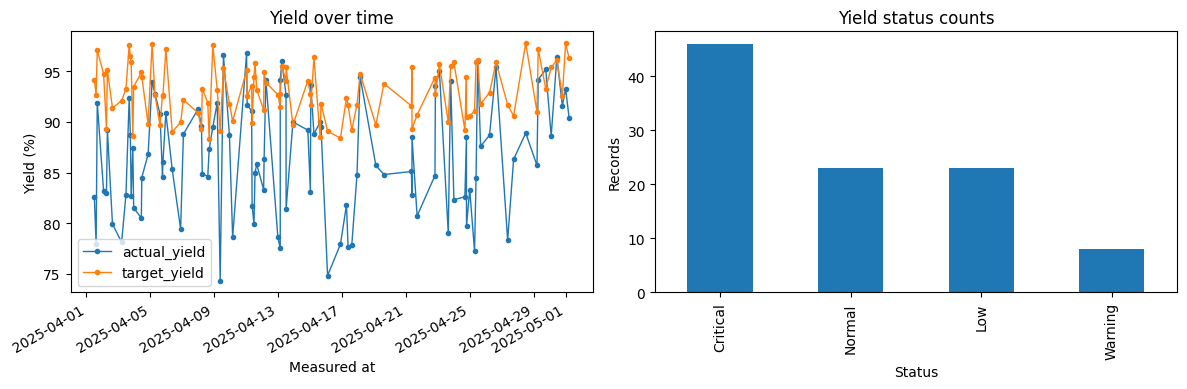

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
y.sort_values('measured_at').plot(x='measured_at', y=['actual_yield','target_yield'], ax=axes[0], marker='.', linewidth=1)
axes[0].set_title('Yield over time'); axes[0].set_xlabel('Measured at'); axes[0].set_ylabel('Yield (%)')
y['yield_status'].map({'정상':'Normal','주의':'Warning','저하':'Low','심각':'Critical'}).value_counts().plot(kind='bar', ax=axes[1], title='Yield status counts')
axes[1].set_xlabel('Status'); axes[1].set_ylabel('Records')
plt.tight_layout(); plt.show()

## 3. 테이블 관계/키 점검: ID 존재 여부와 장비·공정 일관성

In [5]:
p, r, i = (tables[name].copy() for name in ['process_condition','root_cause_analysis','improvement_tracking'])
y_key = y.set_index('yield_id')
result = []
for name, df in [('process_condition', p), ('root_cause_analysis', r), ('improvement_tracking', i)]:
    joined = df.merge(y[['yield_id','equipment_id','process_id']], on='yield_id', how='left', suffixes=('', '_yield'), validate='many_to_one')
    result.append({
        'table': name,
        'missing_yield_id': int(joined['equipment_id_yield'].isna().sum()),
        'equipment_id_mismatch': int((joined['equipment_id'] != joined['equipment_id_yield']).sum()),
        'process_id_mismatch': int((joined['process_id'] != joined['process_id_yield']).sum()),
    })
display(pd.DataFrame(result))
rca_join = i.merge(r[['rca_id','yield_id']], on='rca_id', how='left', suffixes=('', '_rca'), validate='many_to_one')
print('개선 데이터의 RCA yield_id 불일치:', int((rca_join['yield_id'] != rca_join['yield_id_rca']).sum()))
print('참고: yield_id는 하위 테이블에서 중복될 수 있으므로 단순 JOIN은 행이 늘어날 수 있습니다.')

,table,missing_yield_id,equipment_id_mismatch,process_id_mismatch
0,process_condition,0,90,90
1,root_cause_analysis,0,93,89
2,improvement_tracking,0,91,86


개선 데이터의 RCA yield_id 불일치: 100
참고: yield_id는 하위 테이블에서 중복될 수 있으므로 단순 JOIN은 행이 늘어날 수 있습니다.


## 4. 시간 순서 점검 / 개선 진행 상태

In [6]:
yp = y[['yield_id','measured_at']]
p['recorded_at'] = pd.to_datetime(p['recorded_at'])
r['analyzed_at'] = pd.to_datetime(r['analyzed_at'])
p_time = p.merge(yp,on='yield_id',validate='many_to_one')
r_time = r.merge(yp,on='yield_id',validate='many_to_one')
print('조건 기록이 수율 측정보다 나중인 행:', int((p_time['recorded_at'] > p_time['measured_at']).sum()))
print('원인 분석이 수율 측정보다 이전인 행:', int((r_time['analyzed_at'] < r_time['measured_at']).sum()))
display(i['improve_status'].value_counts().rename_axis('상태').to_frame('건수'))
print('개선 후 수율 미기록:', int(i['actual_yield_after'].isna().sum()))

조건 기록이 수율 측정보다 나중인 행: 58
원인 분석이 수율 측정보다 이전인 행: 48


,건수
상태,
진행중,28
완료,26
대기,24
보류,22


개선 후 수율 미기록: 74


## 5. 해석 및 후속 질문

- **확인된 사실:** 각 테이블에 100건이 있으며 키 자체가 없는 사례는 관찰되지 않음.
- **확인 필요:** 같은 `yield_id`의 `equipment_id` / `process_id` 불일치가 다수 관찰됨. `improvement_tracking.rca_id`와 해당 RCA의 `yield_id`도 일치하지 않음.
- **확인 필요:** 수량 기준 수율 산식과 제공 `actual_yield` 수치가 일부 다름. 시간 순서도 업무 프로세스와 일치하는지 확인 필요.
- **주의:** 합성 샘플일 가능성이 있으며, 이 결과로 실공정 이상 원인을 확정해서는 안 됨.

상세 목록 및 1차 데이터 사전: `docs/data_inventory.md`, `docs/data_dictionary.csv`, `docs/data_quality_findings.csv`.